### Libraries

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
import statsmodels.api as sm




### DF

In [3]:
amazon_df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
amazon_df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


## Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

### 1. Crosstab analysis

In [4]:
crosstab_result = pd.crosstab(amazon_df['category'], amazon_df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


Grocery, Health and Baby are the categories where most best sellers are

### 2. Statistical Tests

#### Chi-square

In [5]:
# Chi-square test for 'category' and 'isBestSeller'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

It has a significant relationship between the two variables, as the p-value is less than 0.05. This suggests that the category of a product is associated with whether it is a best seller or not.

#### Compute Cramér's V

In [6]:
# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab_result, method="cramer")

0.1222829439760564

The Cramér's V value of 0.148 suggests a weak association between the two variables. Though statistically significant, the strength of this relationship is not very strong in practical terms.

### 3. Visualizations:


<Axes: xlabel='category'>

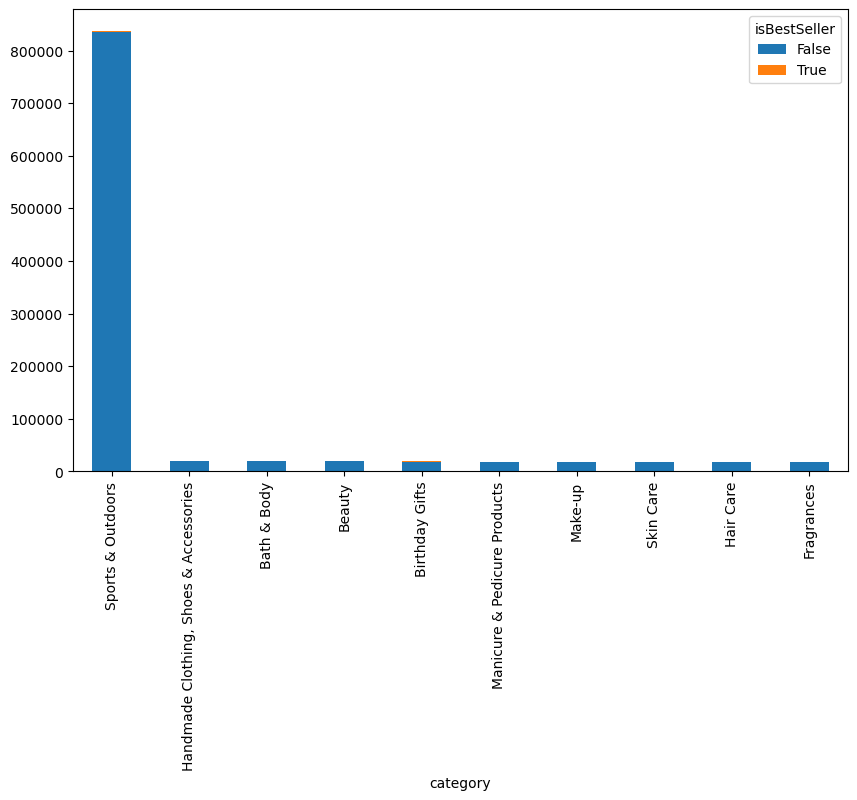

In [7]:
# As there are many categories, we will plot only the top 10 categories based on the count of the 'isBestSeller' variable. We will sort the crosstab_result by the count of 'isBestSeller' and select the top 10 categories for visualization.
crosstab_top_10 = crosstab_result.sort_values(by=[False, True], ascending=False).head(10)
crosstab_top_10.plot(kind="bar", stacked=True, figsize=(10, 6))

## Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

#### 0. Preliminary Analysis

In [8]:
# Tukey's test for outliers
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    return outliers

In [9]:
#Let's apply Tukey's test for outliers on the 'price' columns of the amazon_df DataFrame.
price_series = amazon_df['price']
price_outliers = tukeys_test_outliers(price_series)
price_outliers

10         139.00
19         164.99
25         149.99
28         289.00
31         199.99
            ...  
2443619    166.99
2443627    152.58
2443638    108.77
2443641    166.99
2443643    158.99
Name: price, Length: 327688, dtype: float64

In [20]:
# Remove the rows identified as price outliers from amazon_df.
# We use the original row indices from price_outliers to drop the exact matching rows.
# The ~ means "keep the rows that are not in the outlier index list."
# .copy() creates an independent cleaned dataframe.
amazon_df_clean = amazon_df[~amazon_df.index.isin(price_outliers.index)].copy()

# Display the cleaned dataframe.
amazon_df_clean


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [11]:
#Let's re-check that the outliers have been removed from the 'price' column in the amazon_df_clean DataFrame.
outliers_series = amazon_df_clean['price']
test_outliers = tukeys_test_outliers(outliers_series)
test_outliers

14         64.99
22         64.99
23         98.95
27         79.99
38         74.99
           ...  
2443625    99.95
2443626    71.95
2443628    69.99
2443647    97.99
2443649    79.99
Name: price, Length: 157052, dtype: float64

All good here now.

#### 1. Violin Plots
- Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
- Which product category tends to have the highest median price? Don't filter here by top categories.

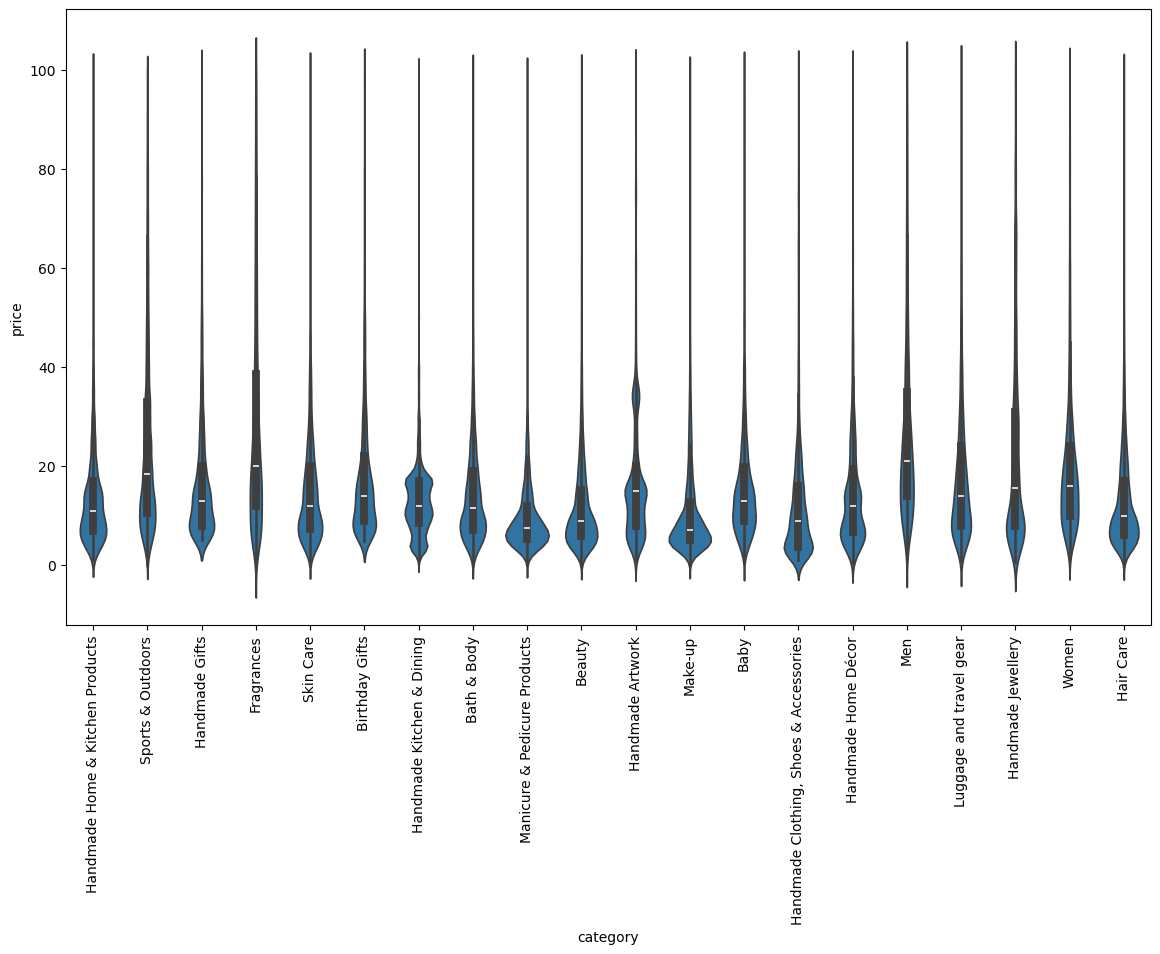

In [19]:
# Select the 20 most frequent categories in the cleaned dataframe.
# This limits the plot to the categories with the highest number of products,
# which makes the visualization easier to read.
top_20_categories = amazon_df_clean['category'].value_counts().head(20).index

# Keep only rows whose category is in the top 20 list.
# We are not changing the price values here; we are only filtering the categories
# that will appear in the violin plot.
df_top20 = amazon_df_clean[
    amazon_df_clean['category'].isin(top_20_categories)
]

# Create the violin plot.
# category is on the x-axis and price is on the y-axis.
plt.figure(figsize=(14, 8))
sns.violinplot(data=df_top20, x='category', y='price')

# Rotate the category labels so they do not overlap.
plt.xticks(rotation=90)

# Show the final plot.
plt.show()


In [25]:
# Which product category tends to have the highest median price? Don't filter here by top categories.

top_median_category = amazon_df_clean.groupby('category')['price'].median().sort_values(ascending=False).head(1)

print(f"The product category with the highest median price is '{top_median_category.index[0]}' with a median price of {top_median_category.values[0]:.2f}.")

The product category with the highest median price is 'Desktop PCs' with a median price of 74.00.


#### 2. Bar Charts
- Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
- Which product category commands the highest average price? Don't filter here by top categories.

/var/folders/b4/svxttqvs5zg_rg_drrxn_vf00000gn/T/ipykernel_63742/2473505557.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top10, x='category', y='price', palette="coolwarm")


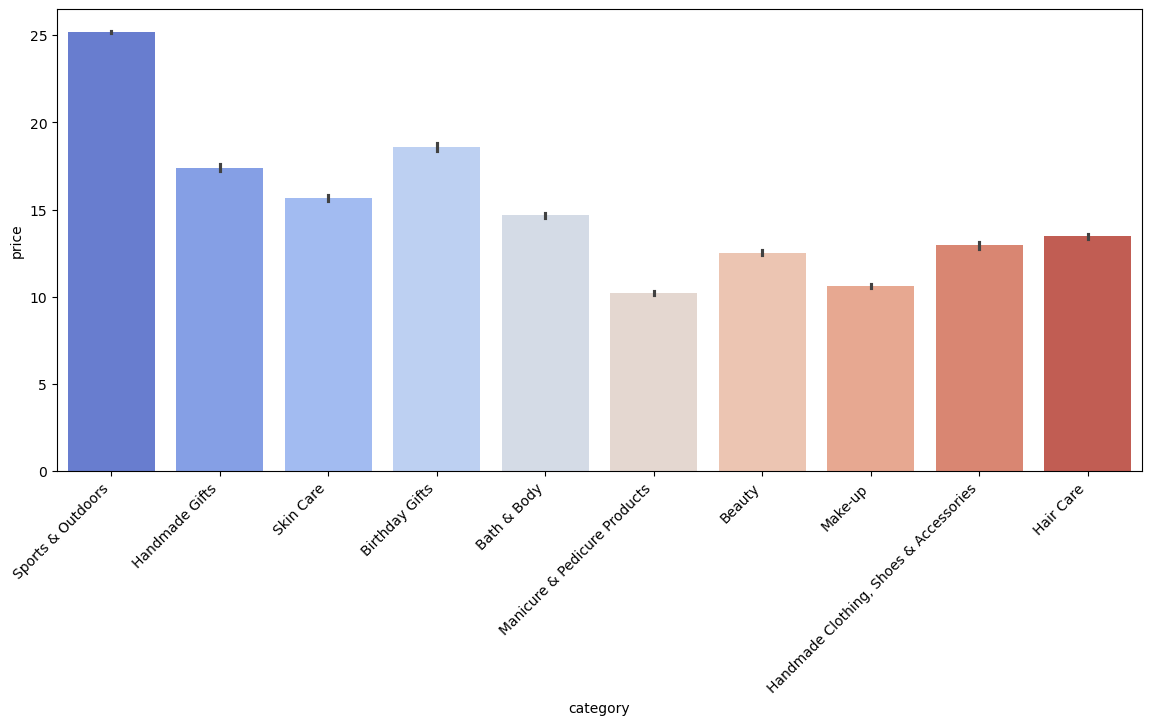

In [32]:
# Select the 20 most frequent categories in the cleaned dataframe.
# This limits the plot to the categories with the highest number of products,
# which makes the visualization easier to read.
top_10_categories = amazon_df_clean['category'].value_counts().head(10).index

# Keep only rows whose category is in the top 10 list.
# We are not changing the price values here; we are only filtering the categories
# that will appear in the violin plot.
df_top10 = amazon_df_clean[
    amazon_df_clean['category'].isin(top_10_categories)
]

plt.figure(figsize=(14, 6))
sns.barplot(data=df_top10, x='category', y='price', palette="coolwarm")
plt.xticks(rotation=45, ha='right')
plt.show()

In [31]:
# Which product category commands the highest average price? Don't filter here by top categories.
top_average_category = amazon_df_clean.groupby('category')['price'].mean().sort_values(ascending=False).head(1)

print(f"The product category with the highest average price is '{top_average_category.index[0]}' with an average price of {top_average_category.values[0]:.2f}.")

The product category with the highest average price is 'Motherboards' with an average price of 68.77.


#### 3. Box Plots
- Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
- Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

/var/folders/b4/svxttqvs5zg_rg_drrxn_vf00000gn/T/ipykernel_63742/2000800655.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x='category', y='stars', palette="coolwarm")


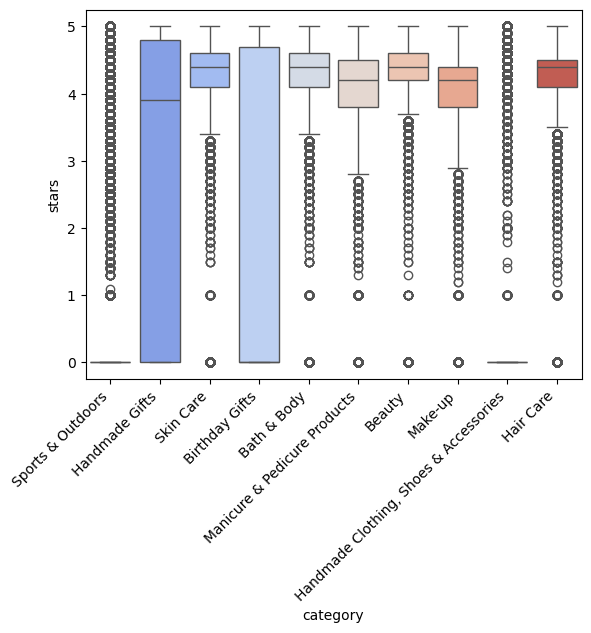

<Figure size 1400x600 with 0 Axes>

In [35]:

sns.boxplot(data=df_top10, x='category', y='stars', palette="coolwarm")
plt.xticks(rotation=45, ha='right')
plt.figure(figsize=(14, 6))
plt.show()

In [36]:
# Which category tends to receive the highest median rating from customers? Don't filter here by top categories.
top_median_category = amazon_df_clean.groupby('category')['stars'].median().sort_values(ascending=False).head(1)

print(f"The product category with the highest median rating is '{top_median_category.index[0]}' with a median rating of {top_median_category.values[0]:.2f}.")

The product category with the highest median rating is 'Computer Memory' with a median rating of 4.70.



## Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 


### 1. Correlation Coefficients:

In [38]:
P_correlation = amazon_df_clean['price'].corr(amazon_df_clean['stars'])
P_correlation

np.float64(-0.0776729987818131)

In [39]:
S_correlation = amazon_df_clean['price'].corr(amazon_df_clean['stars'], method='spearman')
S_correlation

np.float64(-0.06679697280768324)

There is not relationship with price without outliers and stars. Let's check with outliers included:

In [40]:
P2_correlation = amazon_df['price'].corr(amazon_df['stars'])
P2_correlation

np.float64(-0.12490673262148537)

In [41]:
S2_correlation = amazon_df['price'].corr(amazon_df['stars'], method='spearman')
S2_correlation

np.float64(-0.13316425462433998)

There is some association between price and customer ratings, it is not strong enough to make definitive conclusions about their relationship.

What about no price outliers and >0 stars?

In [ ]:
price_stars_df = amazon_df_clean[amazon_df_clean['stars'] > 0].copy()

P_correlation = price_stars_df['price'].corr(price_stars_df['stars'])
P_correlation


np.float64(-0.00491182300075293)

No relationship.

### 2. Visualizations
- Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
- Use a correlation heatmap to visualize correlations between all numerical variables.
- Examine if product prices typically follow a normal distribution using a QQ plot. 


#### Scatterplots

<Axes: xlabel='stars', ylabel='price'>

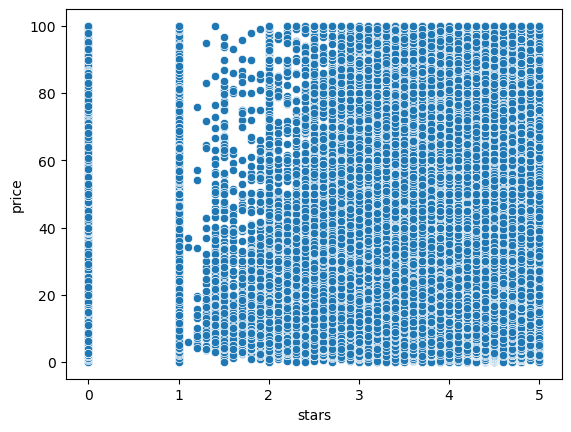

In [49]:
sns.scatterplot(data=amazon_df_clean, x='stars', y='price')

There is not a pattern

<Axes: xlabel='stars', ylabel='price'>

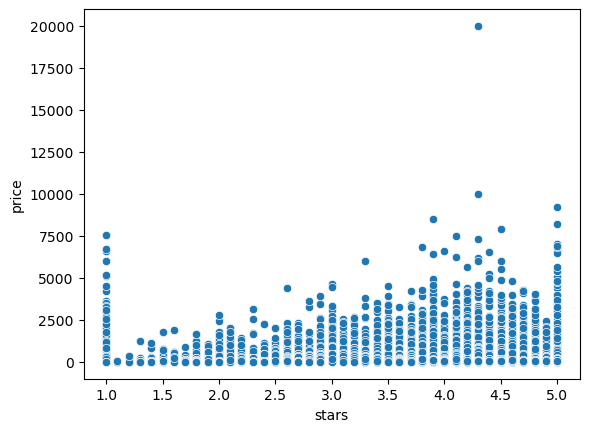

In [50]:
sns.scatterplot(data=price_stars_df, x='stars', y='price')

After removing rows with  stars = 0 , the scatter plot suggests only a very weak positive relationship between rating and price. Although higher-rated products appear slightly more often at higher prices, the overall pattern remains noisy and not strongly linear.

#### Correlation heatmap

In [51]:
amazon_df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2115963 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 147.3+ MB


In [ ]:
# Separating between discrete and continuous variables, as discrete ones could potentially be treated as categorical.
potential_categorical_from_numerical = amazon_df.select_dtypes("number").loc[:, amazon_df.select_dtypes("number").nunique() < 20]

# Explicitly move 'uid' and 'boughtInLastMonth' to the categorical dataframe as well.
# This is useful because 'uid' is an identifier and 'boughtInLastMonth' is a discrete count.
extra_categorical = amazon_df[["uid", "boughtInLastMonth"]]

# Extracting columns with object (typically string) data types to create a categorical dataframe
# Then add the low-cardinality numeric columns plus the two explicitly excluded columns.
df_categorical = pd.concat(
    [amazon_df.select_dtypes("object"), potential_categorical_from_numerical, extra_categorical],
    axis=1
)

# Adjusting the numerical dataframe by removing the moved columns and the two explicitly excluded columns.
df_numerical = amazon_df.select_dtypes("number").drop(
    columns=list(potential_categorical_from_numerical.columns) + ["uid", "boughtInLastMonth"],
    errors="ignore"
)


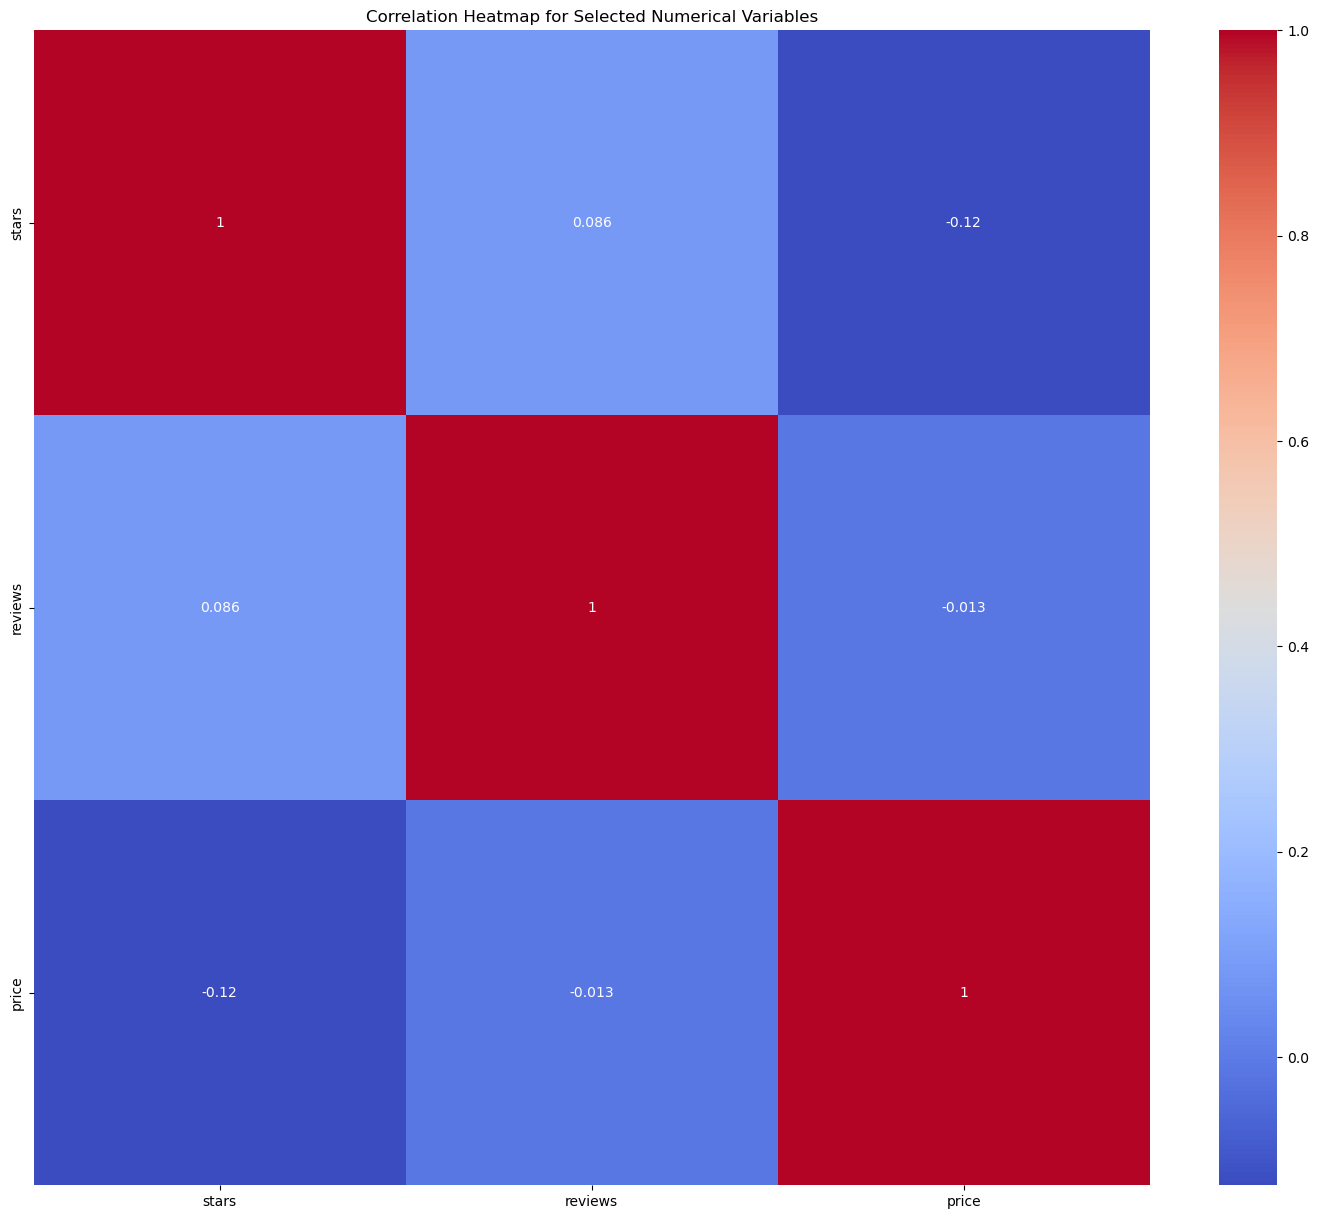

In [57]:
correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

As spotted earlier only very low correlationship between price and stars.

#### QQ

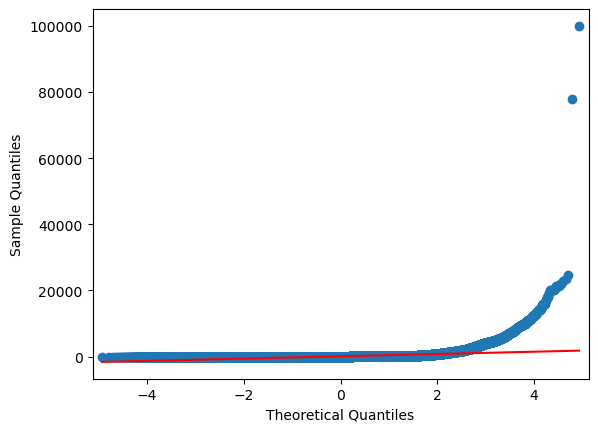

In [ ]:
# Generating a Q-Q plot for 'price' to check if its distribution follows a normal distribution with outliers included.
sm.qqplot(amazon_df['price'], line='s');

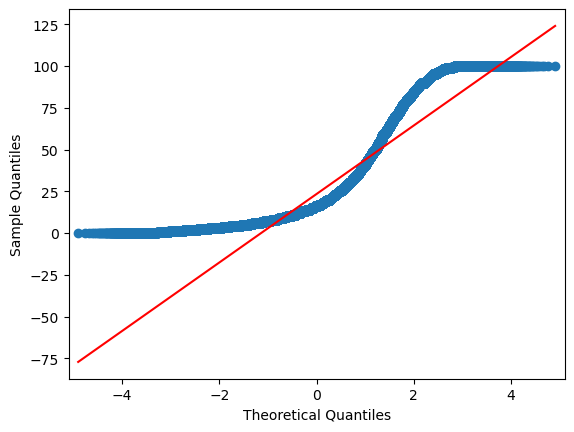

In [61]:
# Generating a Q-Q plot for 'price' to check if its distribution follows a normal distribution with outliers excluded.

sm.qqplot(amazon_df_clean['price'], line='s');